# __VitalSights:__ A Data-Driven Heart Disease Pattern Recovery and Risk Prediction

## A Final Project for the course __CCS 230: Data Mining__
### Submitted by: __Group 1 | JAZL__
### Team Members:
- Cabales, Lean Vince A.
- Calix, Zuriel Eliazar D.
- Escrupulo, Ma. Asherah Francine Faith S.
- Porras, Jessie Loraine P.

__BSCS 3-B AI__

--------------------------------

# __1. SETUP & STATISTICAL SUMMARY__

In [66]:
# Libraries and Dependencies

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [67]:
# Load the dataset

df = pd.read_csv("data/heart.csv")

print("Dataset loaded successfully.")


Dataset loaded successfully.


In [68]:
# Peeking at the data

print("================================================")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("First 10 rows of the heart.csv dataset:")
display(df.head(10))

First 10 rows of the heart.csv dataset:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
5,39,M,NAP,120,339,0,Normal,170,N,0.0,Up,0
6,45,F,ATA,130,237,0,Normal,170,N,0.0,Up,0
7,54,M,ATA,110,208,0,Normal,142,N,0.0,Up,0
8,37,M,ASY,140,207,0,Normal,130,Y,1.5,Flat,1
9,48,F,ATA,120,284,0,Normal,120,N,0.0,Up,0


In [69]:

# Dimension check
print(f"Shape of the heart.csv dataset: {df.shape}")

print("===============================================")

# Structure check
print("Data information of the heart.csv dataset:")
print(df.info())

print("===============================================")

Shape of the heart.csv dataset: (918, 12)
Data information of the heart.csv dataset:
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 97.6 KB
None


In [70]:
print("===============================================")

# Statistical summary
print("Statistical summary of the heart.csv dataset:")
print(df.describe().T)

print("===============================================")

Statistical summary of the heart.csv dataset:
              count        mean         std   min     25%    50%    75%    max
Age           918.0   53.510893    9.432617  28.0   47.00   54.0   60.0   77.0
RestingBP     918.0  132.396514   18.514154   0.0  120.00  130.0  140.0  200.0
Cholesterol   918.0  198.799564  109.384145   0.0  173.25  223.0  267.0  603.0
FastingBS     918.0    0.233115    0.423046   0.0    0.00    0.0    0.0    1.0
MaxHR         918.0  136.809368   25.460334  60.0  120.00  138.0  156.0  202.0
Oldpeak       918.0    0.887364    1.066570  -2.6    0.00    0.6    1.5    6.2
HeartDisease  918.0    0.553377    0.497414   0.0    0.00    1.0    1.0    1.0


# __2. EXPLORATORY DATA ANALYSIS__

In this section, we will perform the Exploratory Data Analysis (EDA) on the dataset guided by the following questions extracted from the __National Heart, Lung, and Blood Institute (NHLBI)'s heart disease risk factors (2022)__:

Access the site here: [Understand Your Risk for Heart Disease](https://www.nhlbi.nih.gov/health/heart-healthy-living/risks)

1. How does the distribution of heart disease cases compare across age groups and sex in our dataset?
2. Can we visually confirm the NHLBI's threshold by creating a histogram or boxplot of age against the target variable, specifically looking for risk spikes at age 45 for males and 55 for females?
3. What is the statistical correlation between Resting Blood Pressure (RestingBP) and the presence of heart disease? Are there significant outliers?
4. Does the dataset show a clear threshold or trend where elevated serum cholesterol significantly increases the likelihood of a positive diagnosis?
5. Assuming Fasting Blood Sugar (FastingBS) > 120 mg/dl indicates diabetic or prediabetic ranges, what percentage of patients with elevated blood sugar also have heart disease compared to those with normal levels?
6. Is there a negative correlation between the maximum heart rate achieved and heart disease risk?
7. How strongly does the presence of exercise-induced angina predict a positive heart disease classification?
8. When generating a correlation matrix (heatmap), which pairs or groups of features (e.g., age + high resting BP + high fasting BS) show the strongest multi-variable association?
9. Can we use pair plots or scatter plots to visually identify clusters of patients who exhibit multiple high-risk metrics simultaneously?


-----------------------------------------------

In [71]:
# Convert DataFrame columns into Python list format for easier reference

df.columns.tolist()

['Age',
 'Sex',
 'ChestPainType',
 'RestingBP',
 'Cholesterol',
 'FastingBS',
 'RestingECG',
 'MaxHR',
 'ExerciseAngina',
 'Oldpeak',
 'ST_Slope',
 'HeartDisease']

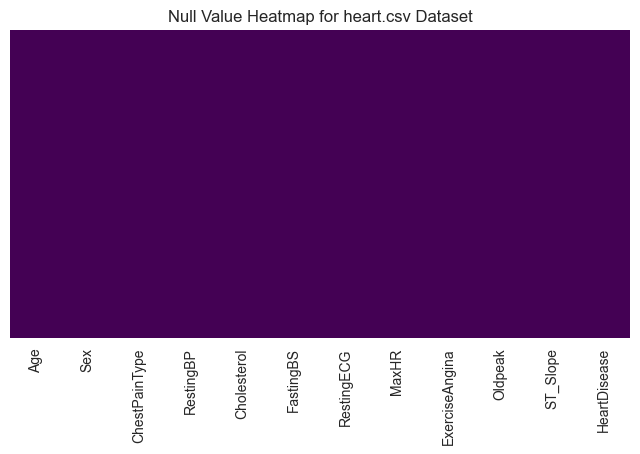

Missing Values Counts:
 Series([], dtype: int64)


In [72]:
# Checking for null values first

plt.figure(figsize=(8, 4))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Null Value Heatmap for heart.csv Dataset")
plt.show()

print("Missing Values Counts:\n", df.isnull().sum()[df.isnull().sum() > 0])


In [73]:
# Checking for duplicate values

duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows in the heart.csv dataset: {duplicate_count}")

Number of duplicate rows in the heart.csv dataset: 0


### __OBSERVATION: The dataset contains no missing values and no duplicate rows. However, further investigation is needed to ascertain that the dataset is ready for model training.__

-----------------------------------------

In [74]:
# Checking for unique values in categorical columns

categorical_cols = df.select_dtypes(include=["object", "category", "str"]).columns
for col in categorical_cols:
    unique_values = df[col].unique()
    print(f"Unique values in '{col}': {unique_values}")

Unique values in 'Sex': <ArrowStringArray>
['M', 'F']
Length: 2, dtype: str
Unique values in 'ChestPainType': <ArrowStringArray>
['ATA', 'NAP', 'ASY', 'TA']
Length: 4, dtype: str
Unique values in 'RestingECG': <ArrowStringArray>
['Normal', 'ST', 'LVH']
Length: 3, dtype: str
Unique values in 'ExerciseAngina': <ArrowStringArray>
['N', 'Y']
Length: 2, dtype: str
Unique values in 'ST_Slope': <ArrowStringArray>
['Up', 'Flat', 'Down']
Length: 3, dtype: str


### __OBSERVATION: The dataset contains 5 categorical columns__

-----------------------------------------

## __UNIVARIATE ANALYSIS: Distribution of Features__

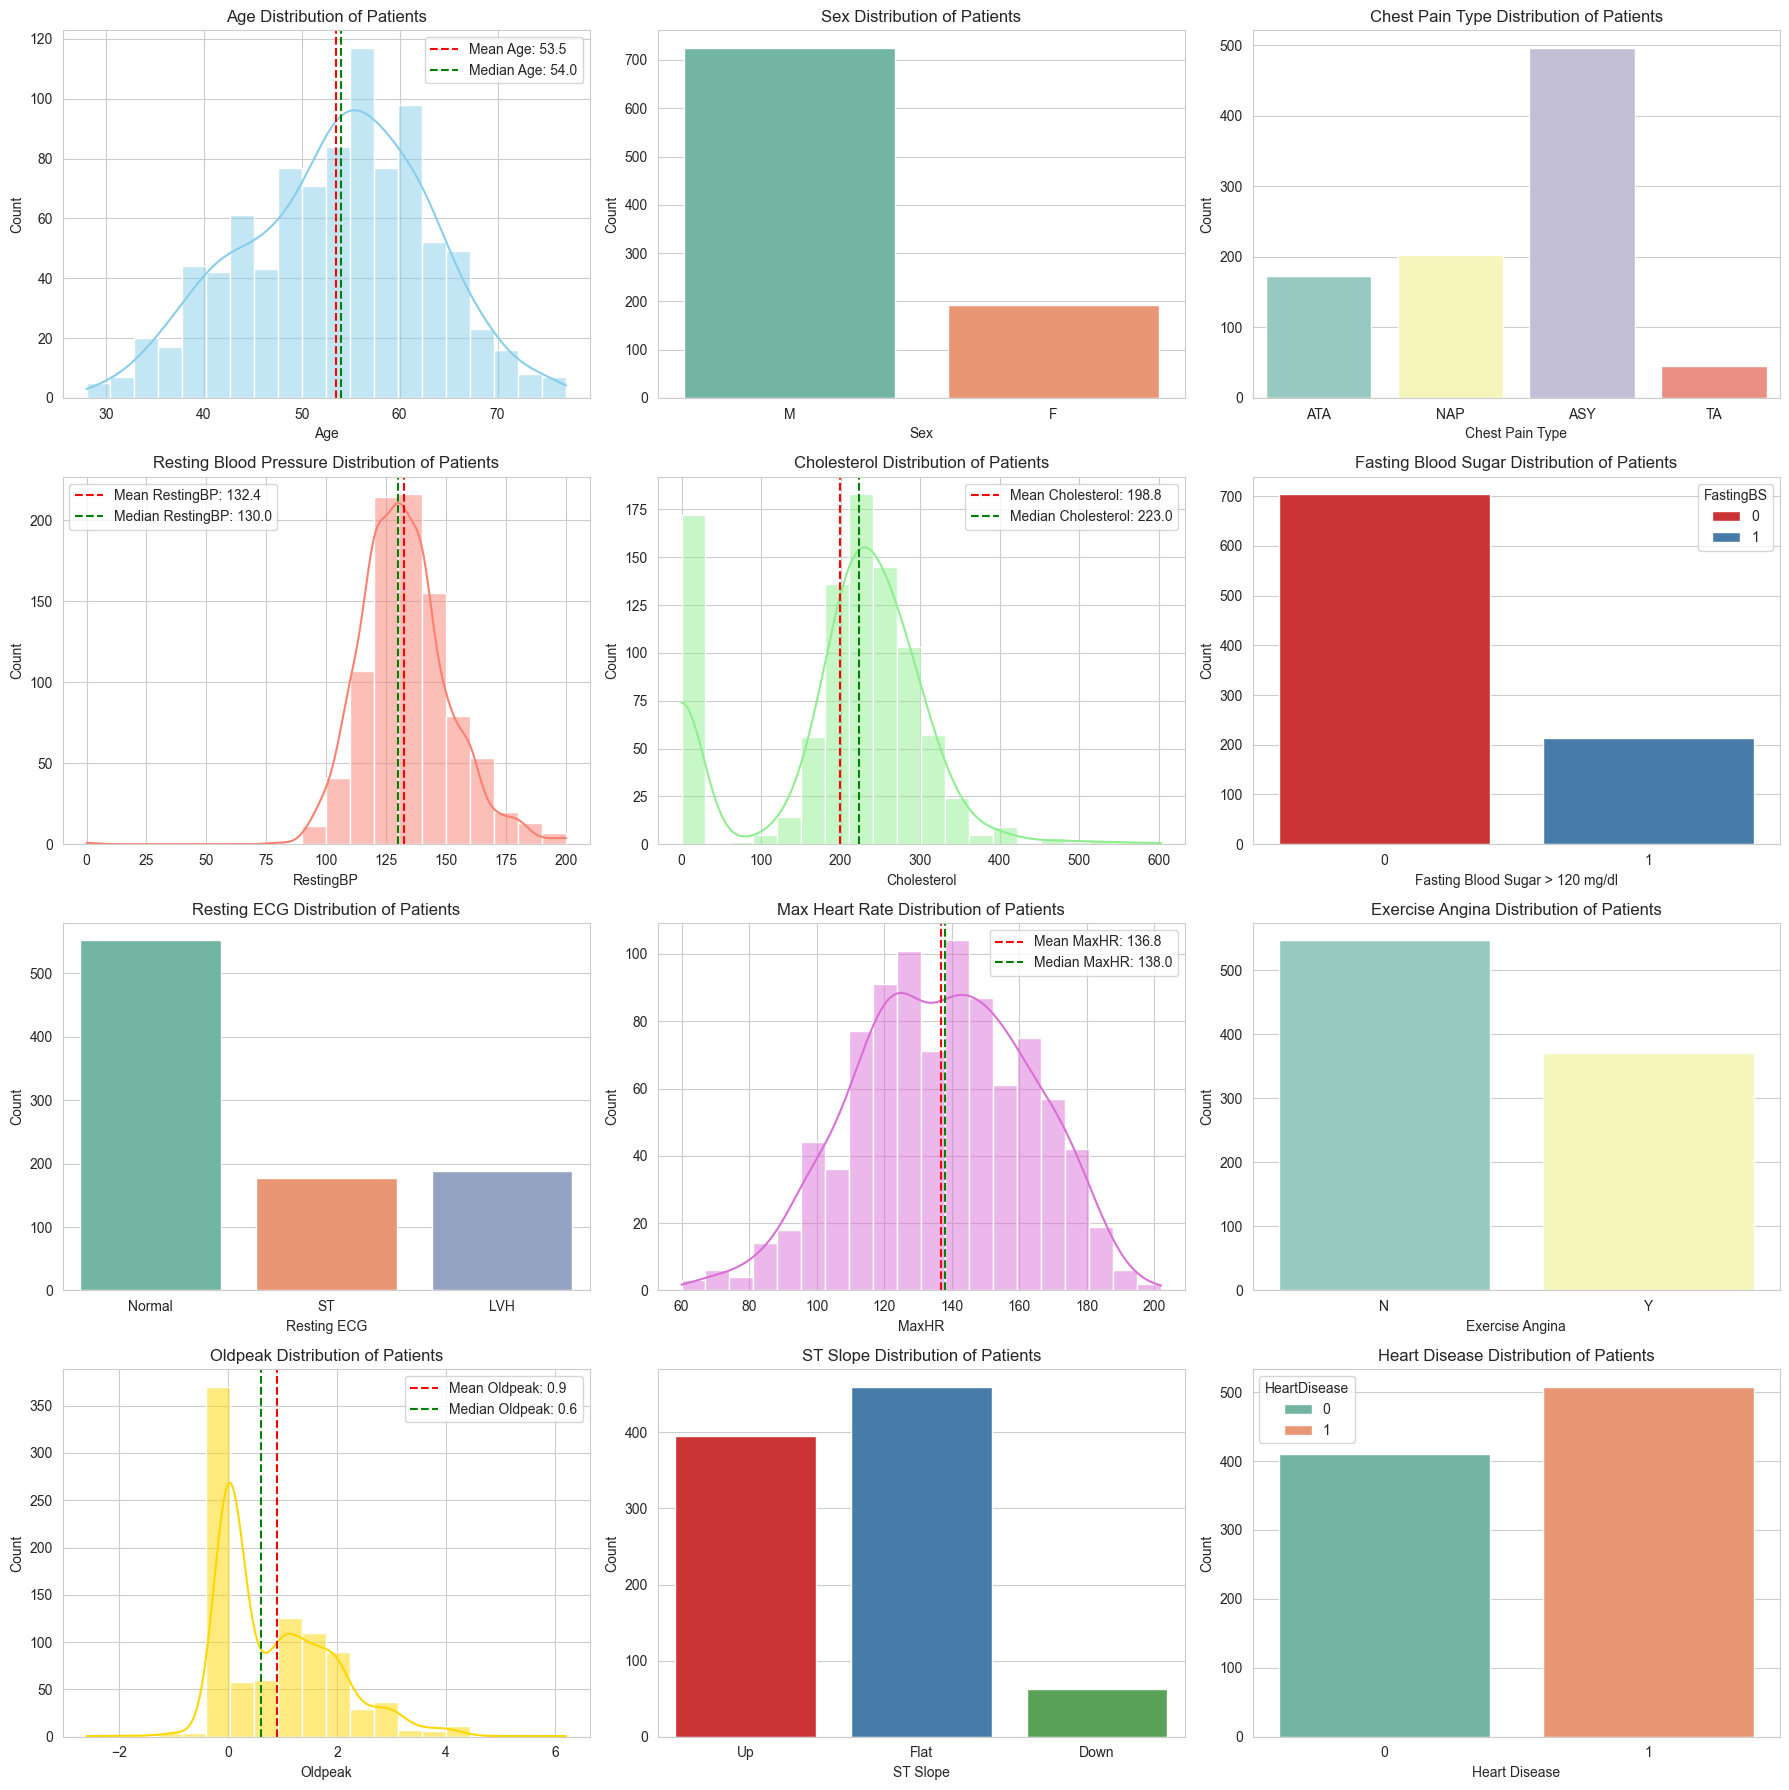

In [75]:
# Histograms for numerical features and count plots for categorical features

plt.figure(figsize=(18, 18))

# Plot 1: Age distribution
plt.subplot(4, 3, 1)
sns.histplot(df["Age"], bins=20, kde=True, color="skyblue")
plt.title("Age Distribution of Patients")
plt.axvline(df["Age"].mean(), color="red", linestyle="--", label=f"Mean Age: {df['Age'].mean():.1f}")
plt.axvline(df["Age"].median(), color="green", linestyle="--", label=f"Median Age: {df['Age'].median():.1f}")
plt.legend()

# Plot 2: Sex distribution
plt.subplot(4, 3, 2)
sns.countplot(x="Sex", data=df, hue="Sex", palette="Set2")
plt.title("Sex Distribution of Patients")
plt.xlabel("Sex")
plt.ylabel("Count")

# Plot 3: Chest Pain Type distribution
plt.subplot(4, 3, 3)
sns.countplot(x="ChestPainType", data=df, hue="ChestPainType", palette="Set3")
plt.title("Chest Pain Type Distribution of Patients")
plt.xlabel("Chest Pain Type")
plt.ylabel("Count")

# Plot 4: Resting Blood Pressure distribution
plt.subplot(4, 3, 4)
sns.histplot(df["RestingBP"], bins=20, kde=True, color="salmon")
plt.title("Resting Blood Pressure Distribution of Patients")
plt.axvline(df["RestingBP"].mean(), color="red", linestyle="--", label=f"Mean RestingBP: {df['RestingBP'].mean():.1f}")
plt.axvline(df["RestingBP"].median(), color="green", linestyle="--", label=f"Median RestingBP: {df['RestingBP'].median():.1f}")
plt.legend()

# Plot 5: Cholesterol distribution
plt.subplot(4, 3, 5)
sns.histplot(df["Cholesterol"], bins=20, kde=True, color="lightgreen")
plt.title("Cholesterol Distribution of Patients")
plt.axvline(df["Cholesterol"].mean(), color="red", linestyle="--", label=f"Mean Cholesterol: {df['Cholesterol'].mean():.1f}")
plt.axvline(df["Cholesterol"].median(), color="green", linestyle="--", label=f"Median Cholesterol: {df['Cholesterol'].median():.1f}")
plt.legend()

# Plot 6: Fasting Blood Sugar distribution
plt.subplot(4, 3, 6)
sns.countplot(x="FastingBS", data=df, hue="FastingBS", palette="Set1")
plt.title("Fasting Blood Sugar Distribution of Patients") 
plt.xlabel("Fasting Blood Sugar > 120 mg/dl")
plt.ylabel("Count")

# Plot 7: Resting ECG distribution
plt.subplot(4, 3, 7)
sns.countplot(x="RestingECG", data=df, hue="RestingECG", palette="Set2")
plt.title("Resting ECG Distribution of Patients")
plt.xlabel("Resting ECG")
plt.ylabel("Count")

# Plot 8: Max Heart Rate distribution
plt.subplot(4, 3, 8)
sns.histplot(df["MaxHR"], bins=20, kde=True, color="orchid")
plt.title("Max Heart Rate Distribution of Patients")
plt.axvline(df["MaxHR"].mean(), color="red", linestyle="--", label=f"Mean MaxHR: {df['MaxHR'].mean():.1f}")
plt.axvline(df["MaxHR"].median(), color="green", linestyle="--", label=f"Median MaxHR: {df['MaxHR'].median():.1f}")
plt.legend()

# Plot 9: Exercise Angina distribution
plt.subplot(4, 3, 9)
sns.countplot(x="ExerciseAngina", data=df, hue="ExerciseAngina", palette="Set3")
plt.title("Exercise Angina Distribution of Patients")
plt.xlabel("Exercise Angina")
plt.ylabel("Count")

# Plot 10: Oldpeak distribution
plt.subplot(4, 3, 10)
sns.histplot(df["Oldpeak"], bins=20, kde=True, color="gold")
plt.title("Oldpeak Distribution of Patients")
plt.axvline(df["Oldpeak"].mean(), color="red", linestyle="--", label=f"Mean Oldpeak: {df['Oldpeak'].mean():.1f}")
plt.axvline(df["Oldpeak"].median(), color="green", linestyle="--", label=f"Median Oldpeak: {df['Oldpeak'].median():.1f}")
plt.legend()

# Plot 11: ST Slope distribution
plt.subplot(4, 3, 11)
sns.countplot(x="ST_Slope", data=df, hue="ST_Slope", palette="Set1")
plt.title("ST Slope Distribution of Patients")
plt.xlabel("ST Slope")
plt.ylabel("Count") 

# Plot 12: Heart Disease distribution
plt.subplot(4, 3, 12)
sns.countplot(x="HeartDisease", data=df, hue="HeartDisease", palette="Set2")
plt.title("Heart Disease Distribution of Patients")
plt.xlabel("Heart Disease")
plt.ylabel("Count")


plt.tight_layout()
plt.show()



## __OBSERVATION:__

- __AGE:__ The age distribution isn't heavily skewed, since the mean and median are close (53.5 and 54.0, respectively). Most patients are between 40 to 60 years old, with a few outliers in the 20s and 70s.

- __SEX:__ More than 700 of the patients are male while there are not less than 200 female patients. This is a significant imbalance in the dataset, which may affect the performance of machine learning models trained on this data.

- __CHEST PAIN TYPE:__ Most patients experience the ASY chest pain type (~490+), followed by NAP (200), ATA (<200), and the least common being TA (<50).

- __RESTING BLOOD PRESSURE:__ The resting blood pressure (RestingBP) has a mean of __132.4mm Hg__, which is slightly higher than the median of 130mm Hg, which would indicate a slight __right skew__ in the distribution. According to NHLBI, NIH (2024), a normal resting blood pressure is less than 120/80mm Hg. However, both the mean and median are above the normal range, assuming that RestingBP represents Systolic Blood Pressure.  This suggests that a significant portion of the patients in the dataset have high blood pressure, which is a known risk factor for heart disease.

- __CHOLESTEROL:__ The mean cholesterol level is __198.8 mg/dl__, which is lower than the median of __223.0 mg/dl__. This indicates a negative (left) skew in the distribution. According to Cleveland Clinic (2025),  a normal total cholesterol level should be less than 200 mg/dl. While the mean is just below the normal threshold, the median or the middle value is above it. This would suggest that more than half of the patients in the dataset have borderline high cholesterol. This is a significant finding since even though borderline high cholesterol is easier to manage than high cholesterol, it still increases the risk of heart disease. __Furthermore, there are at least 170 patients with 0 cholesterol levels, which is likely an error in the dataset and should be investigated further__.

- __FASTING BLOOD SUGAR:__ The specified clinical threshold given in the dataset for fasting blood sugar is > 120 mg/dl, which indicates diabetic or prediabetic ranges. Since the column values are binary (0 or 1), this means that 1 represents patients with a fasting blood dugar over 120 mg/dl, while 0 means patients with normal fasting blood sugar levels. In the dataset, there are an estimated of 210 patients with high fasting blood sugar levels (1) or approximately 23%.

- __RESTING ELECTROCARDIOGRAPHIC RESULTS (RestingECG):__ The bar graph shows that the majority of patients have a normal result (~500+), followed by left ventricular hypertrophy (~190), and ST-T wave abnormalities (~180).

- __MAX HEART RATE:__ The mean maximum heart rate achieved is __136.8 bpm__, which is slightly lower than the median of __138.0 bpm__. This indicates a slightly left-skewed distribution. Since normal max heart rates differ by age, further analysis would be needed to truly determine if this is a concerning value. 

- __EXERCISE INDUCED ANGINA:__ The bar graph shows that most patients (500+) do not experience exercise-induced angina (0), while a smaller portion of patients (360+) do experience it (1).

- __OLDPEAK:__ It is the ST depression induced by exercise relative to rest. The mean oldpeak value is __0.9__, which is slightly higher than the median of __0.6__. This indicates a slight right skew in the distribution. A normal oldpeak level is typically 0 or close to 0. While there is a massive spike at 0 (350+ patients), there are also a significant number of patients with elevated oldpeak values, which could indicate a higher risk of heart disease as their hearts are struggling for oxygen during exercise.

- __ST SLOPE:__ The ST slope measures the angle or direction of the ST segment as the heart tries to recover from exercise (Venkatesan, 2009). The bar graph shows that most patients have a flat ST slope (0) (450+), followed by an upsloping ST slope (1) (~390), and the least common is a downsloping ST slope (2) (~70).

- __HEART DISEASE:__ The bar graph shows that there are more patients with heart disease (1) (500+) than patients without heart disease (0) (~410).


--------------------------------------------------

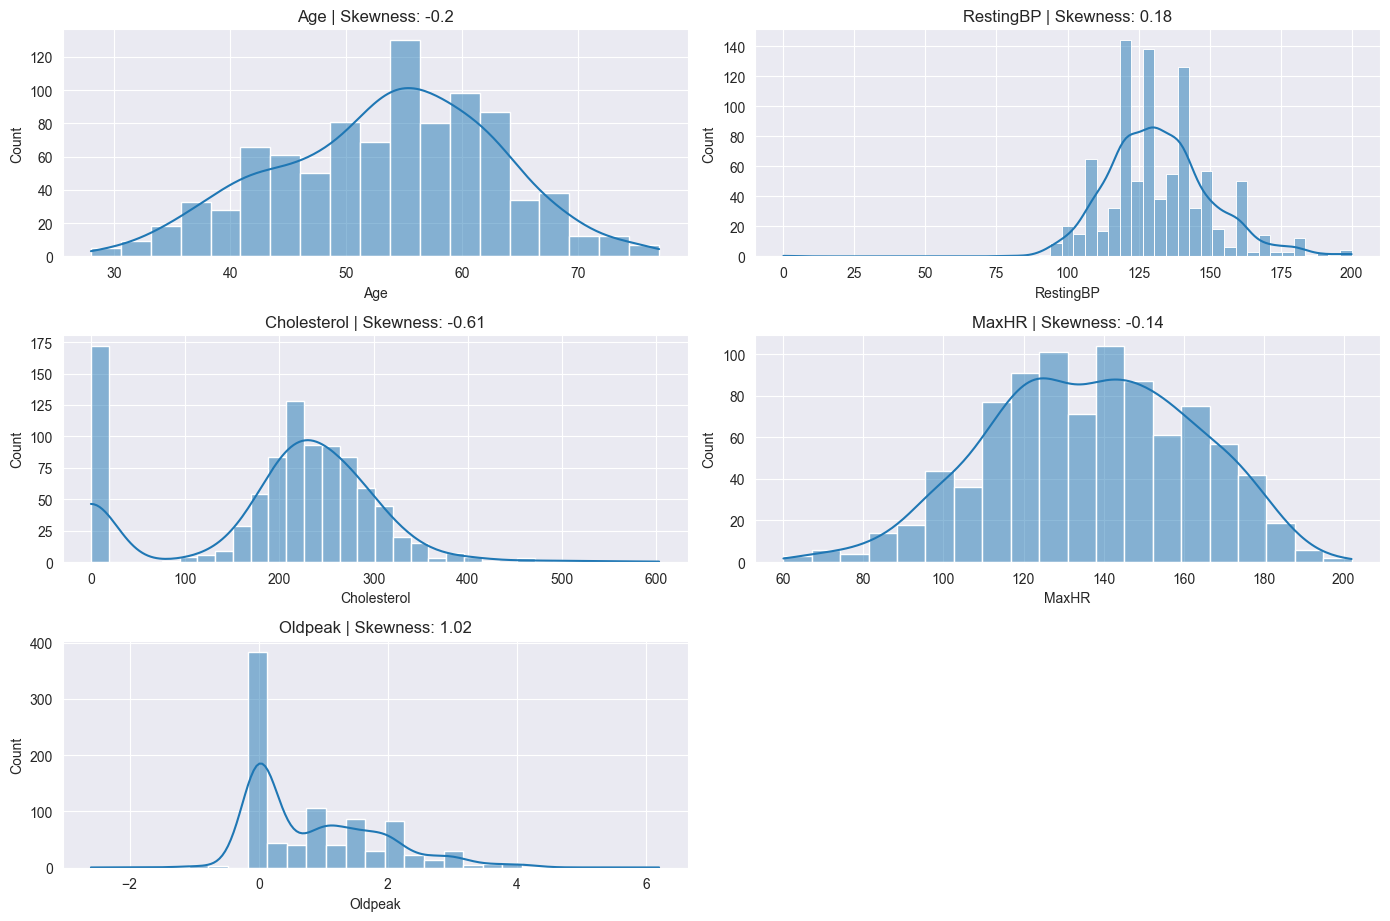

In [76]:
# Kernel Density Estimate (KDE) plots for numerical features for better visualization of distributions

sns.set_style("darkgrid")

numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns.drop(["FastingBS", "HeartDisease"])
plt.figure(figsize=(14, len(numerical_cols) * 3))
for idx, feature in enumerate(numerical_cols, 1):
    plt.subplot(len(numerical_cols), 2, idx)
    sns.histplot(df[feature], kde=True)
    plt.title(f"{feature} | Skewness: {round(df[feature].skew(), 2)}")

plt.tight_layout()
plt.show()


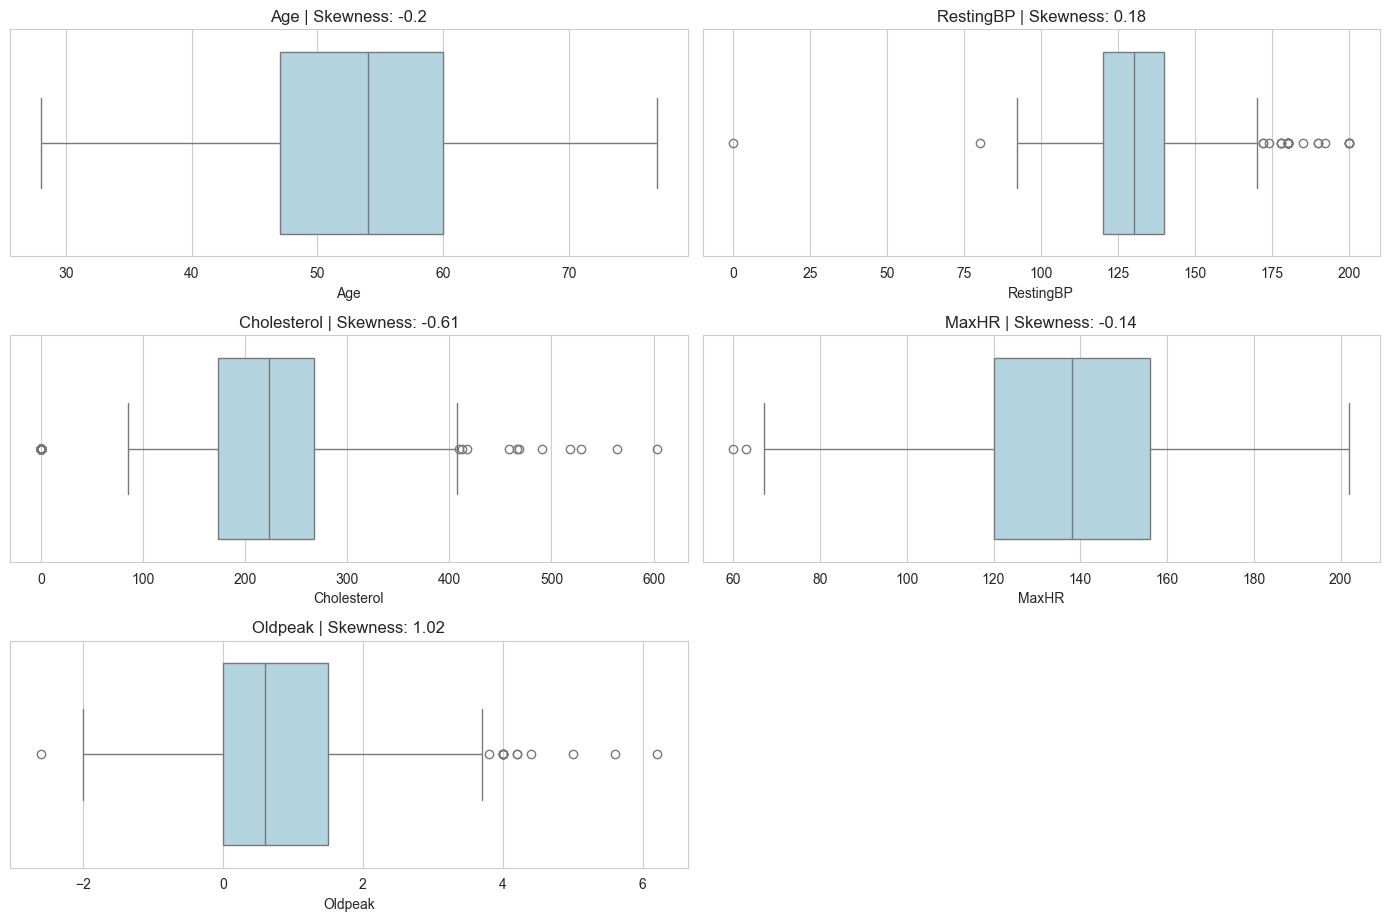

In [77]:
# Detecting outliers using box plots for numerical features

sns.set_style("whitegrid")
numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns.drop(["FastingBS", "HeartDisease"])
plt.figure(figsize=(14, len(numerical_cols) * 3))
for idx, feature in enumerate(numerical_cols, 1):
    plt.subplot(len(numerical_cols), 2, idx)
    sns.boxplot(x=df[feature], color="lightblue")
    plt.title(f"{feature} | Skewness: {round(df[feature].skew(), 2)}")
plt.tight_layout()
plt.show()

## __OBSERVATION:__ 

- The RestingBP column has a patient with 0 mm Hg, which is likely an error in the dataset. The same goes for the Cholesterol column, which has at least 170 patients with 0 mg/dl cholesterol levels. These values may need to be removed or imputed before training machine learning models on this dataset.

- This proves that the dataset is in need of further cleaning and preprocessing even though their are no missing values or duplicate rows detected before. 

- However, the outliers on the far right of the boxplots are considered medical outliers, hence, they should be preserved in the dataset as they represent real patients with high blood pressure and cholesterol levels, which are important for training machine learning models to predict heart disease risk.

-------------------------------------------

## __HANDLING ZERO OUTLIERS IN RESTINGBP AND CHOLESTEROL__

In [78]:
print("================================================")

# Replace the impossible 0s with NaN first
df['RestingBP'] = df['RestingBP'].replace(0, np.nan)
df['Cholesterol'] = df['Cholesterol'].replace(0, np.nan)

# then fill them with the median of their respective columns
df['RestingBP'] = df['RestingBP'].fillna(df['RestingBP'].median())
df['Cholesterol'] = df['Cholesterol'].fillna(df['Cholesterol'].median())

# 3. Print the new minimums to verify the 0s are gone!
print("New Minimum RestingBP:", df['RestingBP'].min())
print("New Minimum Cholesterol:", df['Cholesterol'].min())

print("================================================")

New Minimum RestingBP: 80.0
New Minimum Cholesterol: 85.0


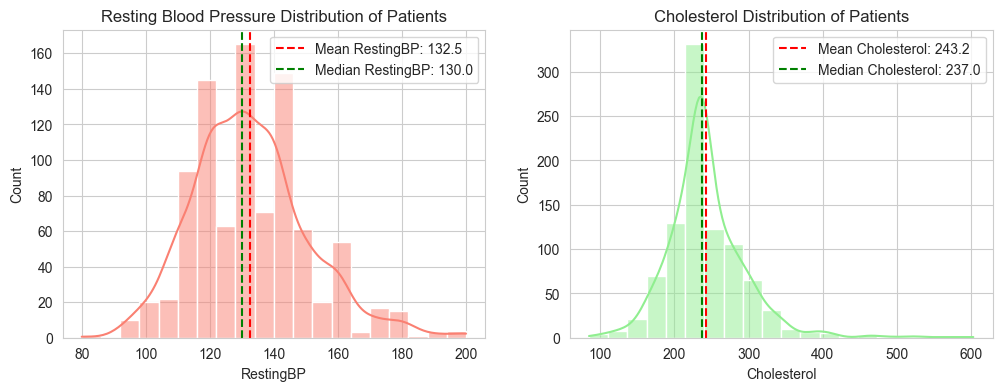

In [79]:
# Checking Cholesterol and RestingBP distributions again after handling the 0 outliers


plt.figure(figsize=(12, 4))
# Resting Blood Pressure distribution
plt.subplot(1, 2, 1)
sns.histplot(df["RestingBP"], bins=20, kde=True, color="salmon")
plt.title("Resting Blood Pressure Distribution of Patients")
plt.axvline(df["RestingBP"].mean(), color="red", linestyle="--", label=f"Mean RestingBP: {df['RestingBP'].mean():.1f}")
plt.axvline(df["RestingBP"].median(), color="green", linestyle="--", label=f"Median RestingBP: {df['RestingBP'].median():.1f}")
plt.legend()

# Cholesterol distribution
plt.subplot(1, 2, 2)
sns.histplot(df["Cholesterol"], bins=20, kde=True, color="lightgreen")
plt.title("Cholesterol Distribution of Patients")
plt.axvline(df["Cholesterol"].mean(), color="red", linestyle="--", label=f"Mean Cholesterol: {df['Cholesterol'].mean():.1f}")
plt.axvline(df["Cholesterol"].median(), color="green", linestyle="--", label=f"Median Cholesterol: {df['Cholesterol'].median():.1f}")
plt.legend()

## __OBSERVATION:__ 

- There are no zero values in both the columns anymore, which means that the impossible outliers have been successfully handled.

------------------------------------------------------

## __BIVARIATE ANALYSIS: Distribution of Heart Disease Cases Across 11 Features__

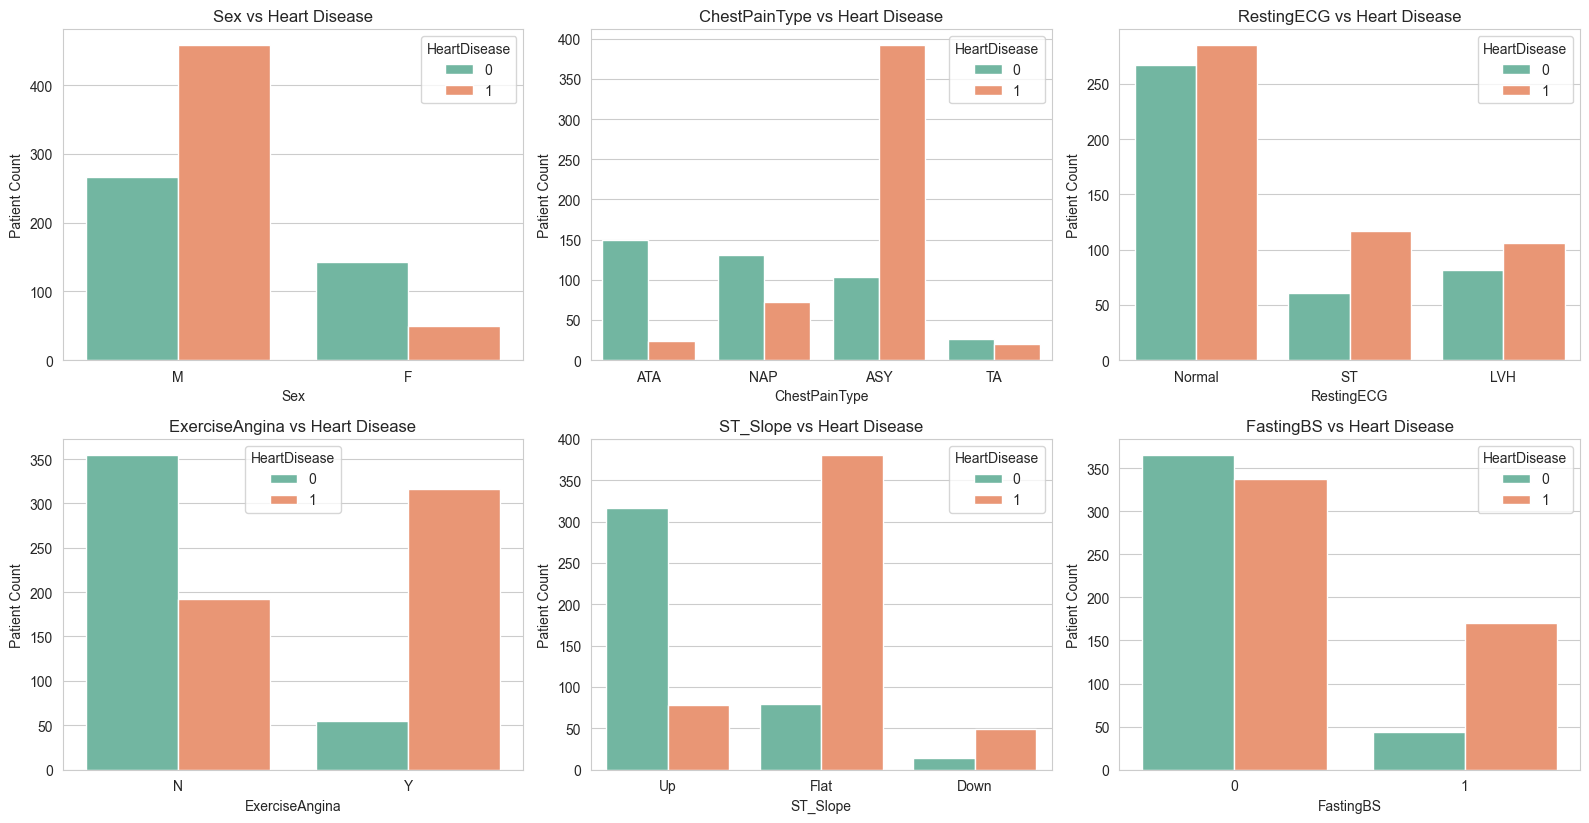

In [80]:
# Categorical features count plots with hue based on HeartDisease

sns.set_style("whitegrid")

# Grab categorical columns and add the binary FastingBS
cat_cols = df.select_dtypes(include=["object", "category", "str"]).columns.tolist()
if "FastingBS" not in cat_cols:
    cat_cols.append("FastingBS")

# Set up the 3x3 grid
plt.figure(figsize=(16, 12))

for idx, feature in enumerate(cat_cols, 1):
    plt.subplot(3, 3, idx)
    # hue="HeartDisease" splits the data by our target variable
    sns.countplot(data=df, x=feature, hue="HeartDisease", palette="Set2")
    plt.title(f"{feature} vs Heart Disease")
    plt.xlabel(feature)
    plt.ylabel("Patient Count")

plt.tight_layout()
plt.show()

## __OBSERVATION:__

- Over 450 of male patients have heart disease while there are less female patients with heart disease. This makes it a massive risk indicator for heart disease. 
- Patients who experience ASY chest pain type have a higher percentage of heart disease cases compared to the other chest pain types. This also makes it a strong predictor of heart disease. 
- Most heart disease cases occur with patients who have normal restingECG results, however, it can be observed that patients with ST and LVH restingECG results have a higher proportionate risk (likelihood) of having a heart disease compared to those with normal restingECG results.
- Patients with exercise-induced angina have a higher percentage of heart disease cases compared to those without exercise-induced angina.
- Patients with a flat ST slope have a higher percentage of heart disease cases compared to those with upsloping and downsloping ST slopes.
- Patients with normal blood sugar can also have heart disease, but a vast majority of patients with high fasting blood sugar levels have heart disease. This makes it a strong predictor of heart disease.

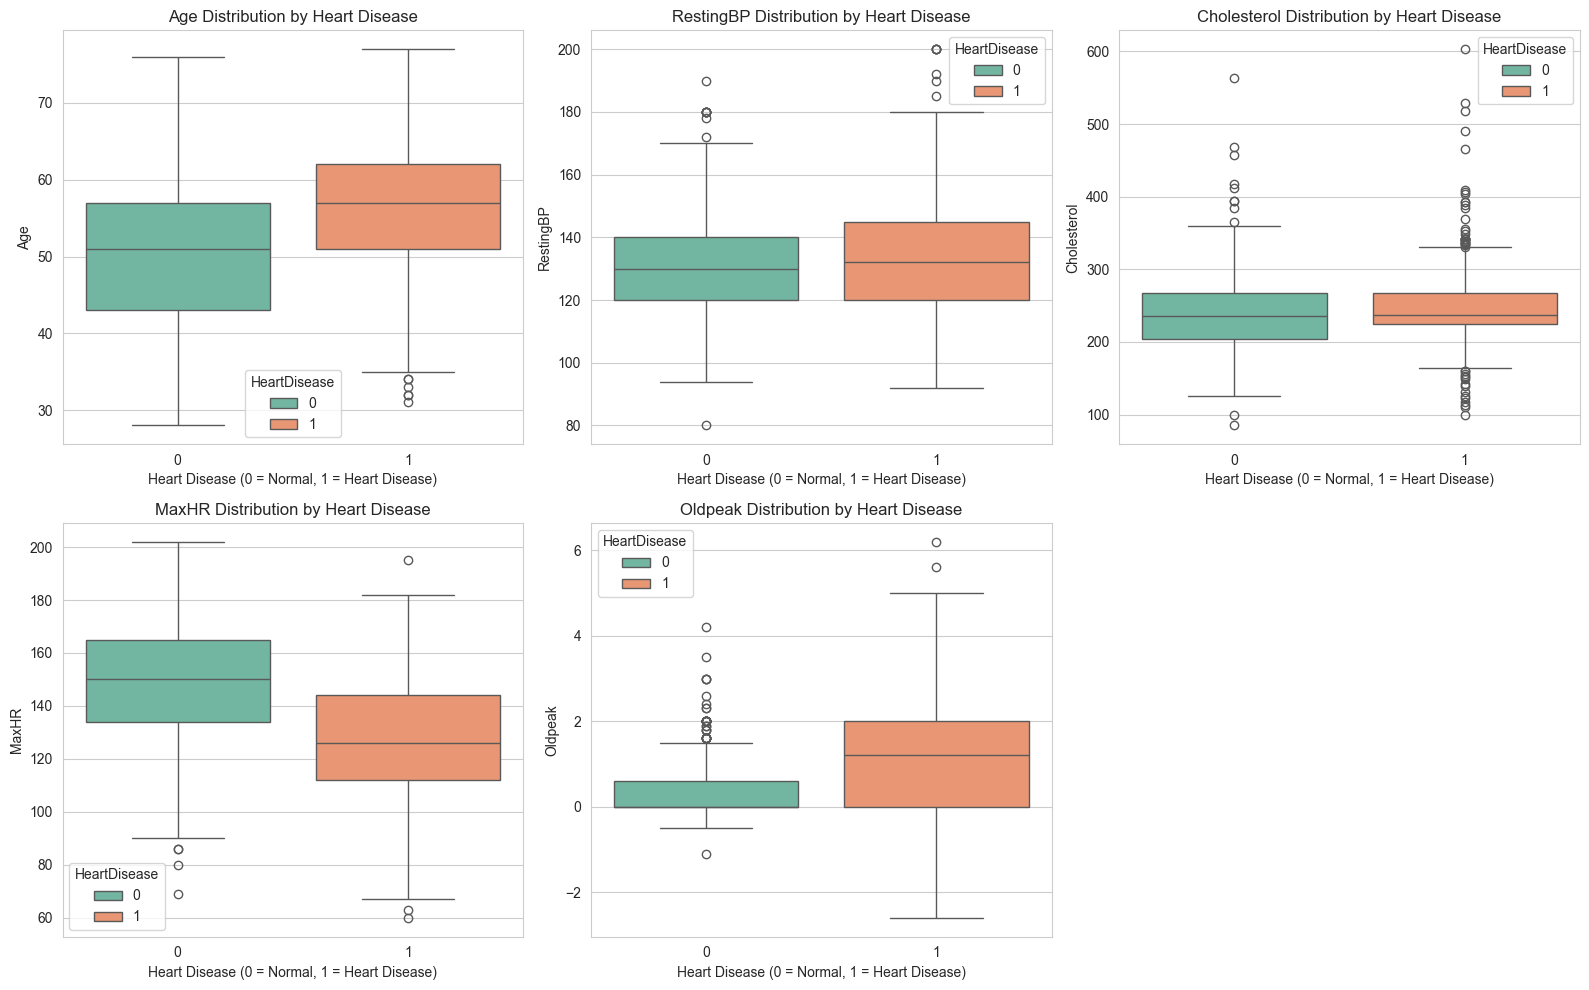

In [81]:
# Numerical features box plots with hue based on HeartDisease

num_cols = df.select_dtypes(include=["int64", "float64"]).columns.drop(["FastingBS", "HeartDisease"])

plt.figure(figsize=(16, 10))

for idx, feature in enumerate(num_cols, 1):
    plt.subplot(2, 3, idx)
    sns.boxplot(data=df, x="HeartDisease", y=feature, hue="HeartDisease", palette="Set2")
    plt.title(f"{feature} Distribution by Heart Disease")
    plt.xlabel("Heart Disease (0 = Normal, 1 = Heart Disease)")
    plt.ylabel(feature)

plt.tight_layout()
plt.show()

## __Observation:__

- Patients with heart disease are mostly around 51 to 63 years old, with a few patients in their 30s having heart disease as well. 
- Most patients with normal resting blood pressure levels do not exceed 140 mm Hg, while there are some outliers that goes beyond 160 mm Hg. Resting blood pressure may not be a strong predictor of heart disease in this case since patients with normal and high resting blood pressure levels almost have a similar distribution.
- Most patients have bordeline high and high cholesterol levels. However, patients with heart disease tend to have a starting cholesterol level of around 220 mg/dl, but it is not really a strong predictor since there are many patients with low cholesterol levels who also have heart disease.
- Patients with heart disease tend to have a lower maximum heart rate compared to those without heart disease. 
- Patients with no heart disease are mostly clustered at 0 oldpeak value, while most patients with heart disease tend to have a higher oldpeak value (more than 1 and even reaching up to 6). This makes a strong predictor for heart disease. 

---------------------------------------------------

## __MULTIVARIATE ANALYSIS: CORRELATION AND PAIR PLOTOF HEART DISEASE CASES ACROSS MULTIPLE FEATURES__

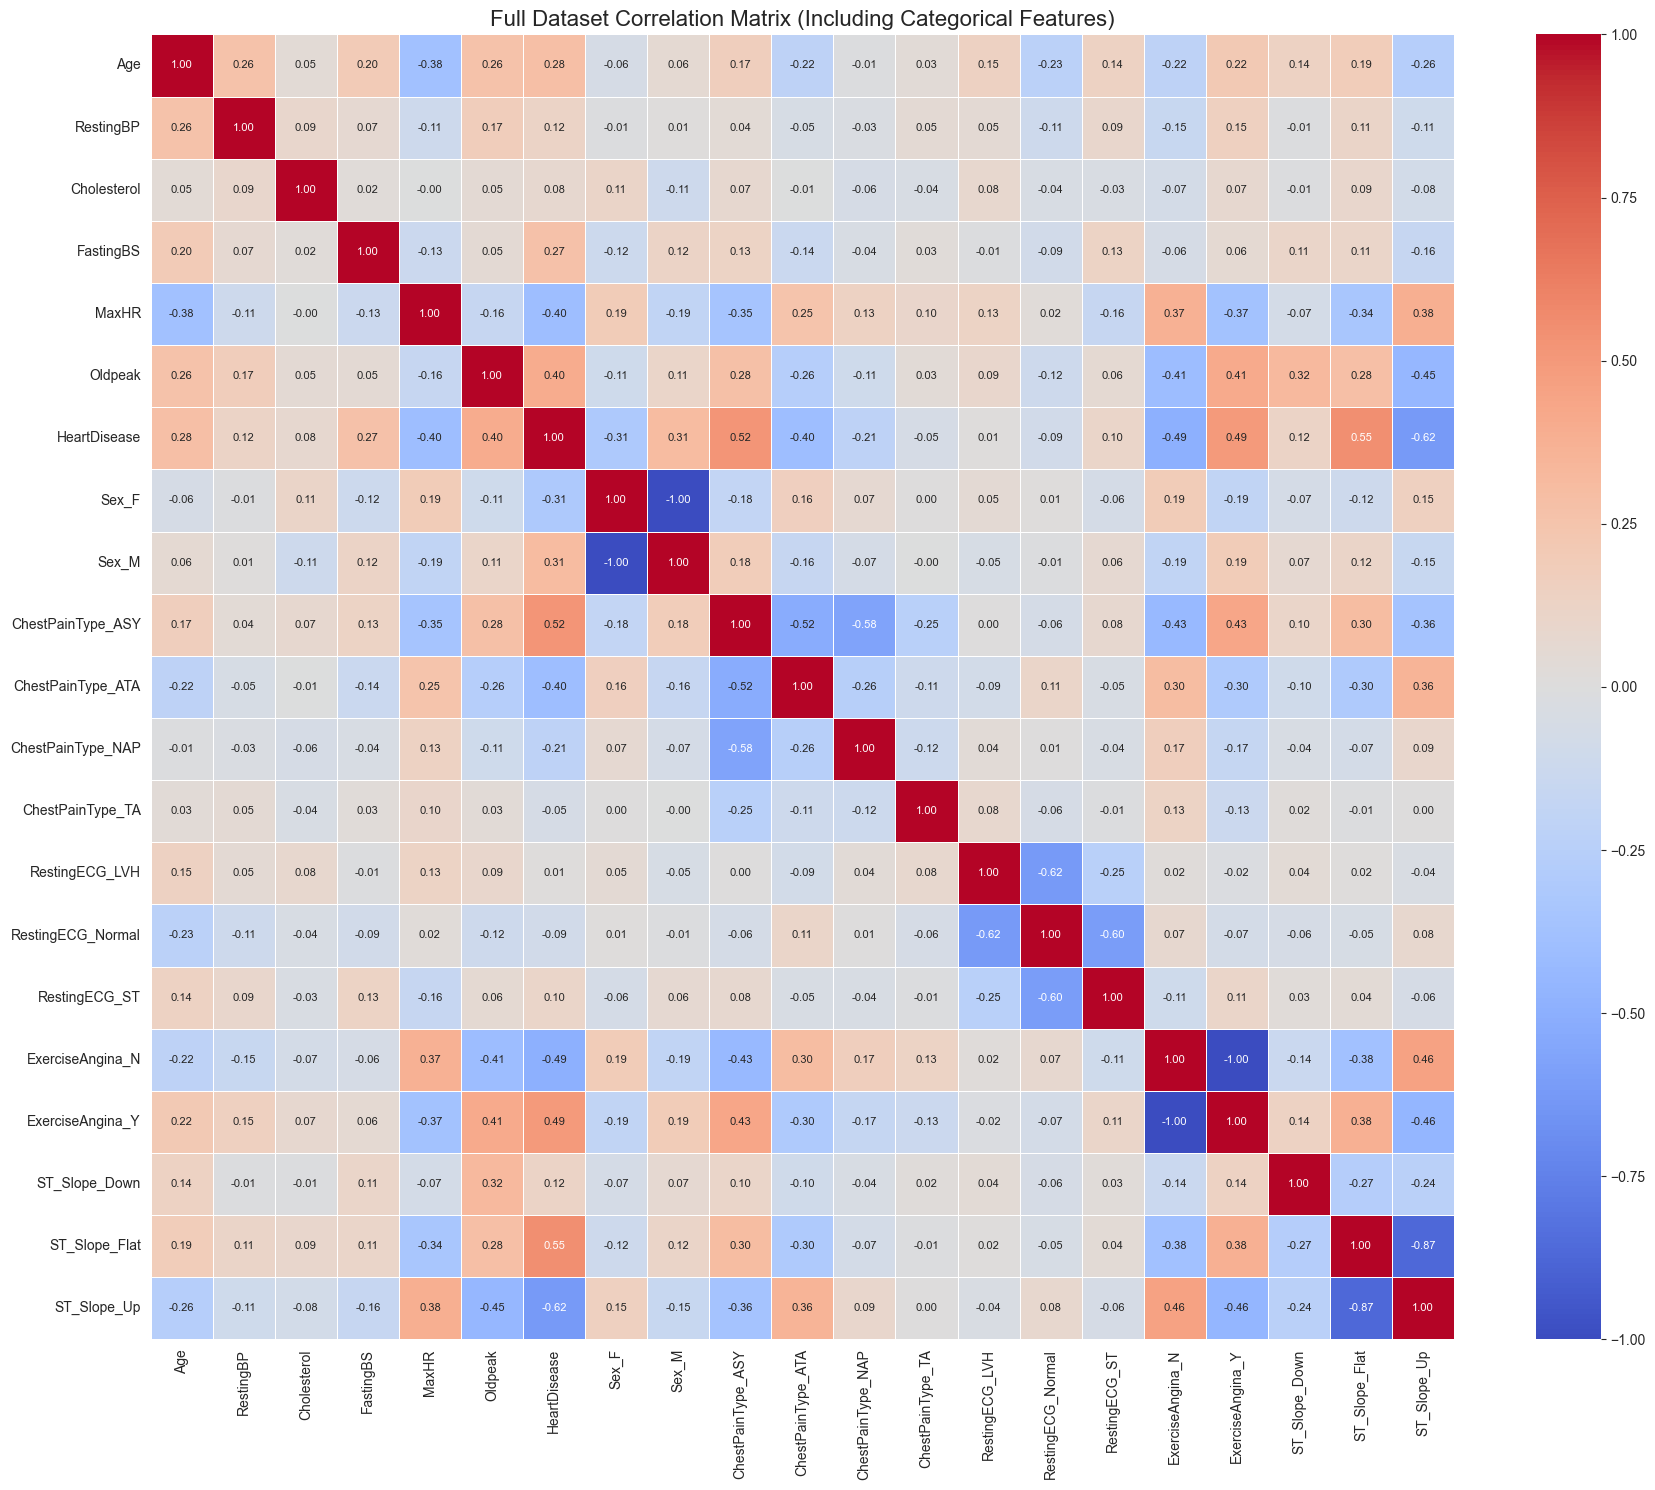

In [84]:
# Correlation matrix (heatmap)


# Convert categorical text columns into 1s and 0s
df_encoded = pd.get_dummies(df)

# Calculate the correlation matrix for all the features
corr_encoded = df_encoded.corr()
plt.figure(figsize=(18, 15))
sns.heatmap(corr_encoded, annot=True, cmap="coolwarm", fmt=".2f", 
            linewidths=0.5, vmin=-1, vmax=1, annot_kws={"size": 8})
plt.title("Full Dataset Correlation Matrix (Including Categorical Features)", fontsize=16)
plt.tight_layout()
plt.show()

## __OBSERVATION:__ 

- Based on the correlation matrix for all the dataset's features, the features that show the __strongest positive correlation__ with heart disease are:

        - Flat: ST Slope (0.55)
        - ASY: chest pain type (0.52)
        - Yes: Exercise Induced Angina (0.49)

- Other features that show a positive correlation with heart disease but not as strong as the top 3 are:

        - Oldpeak (0.40)
        - Male: Sex (0.31)        
        - Age (0.28)
        - Fasting Blood Sugar (0.27)
        
- The features that show the __strongest negative correlation__ with heart disease are:

        - Upsloping: ST Slope (-0.62)
        - No: Exercise Induced Angina (-0.49)
        - Max Heart Rate (-0.40)
        - ATA: Chest Pain Type (-0.40)
        - Female: Sex (-0.31)
        - NAP: Chest Pain Type (-0.21)

- Based on this results, we can conclude that the feature with the __highest correlation with heart disease is the ST Slope__, specifically the __Upsloping (-0.62) and the Flat slope (0.55)__. This means that the behavior of the heart's recovery after exercise is the most important factor in determining heart disease risk in this dataset. __MaxHR and Oldpeak shows equal importance__ as well, with a correlation of -0.40 and 0.40, respectively. This means that __patients with heart disease tend to have a lower maximum heart rate and a higher oldpeak value compared to patients without heart disease.__


--------------------------------------------------
                      

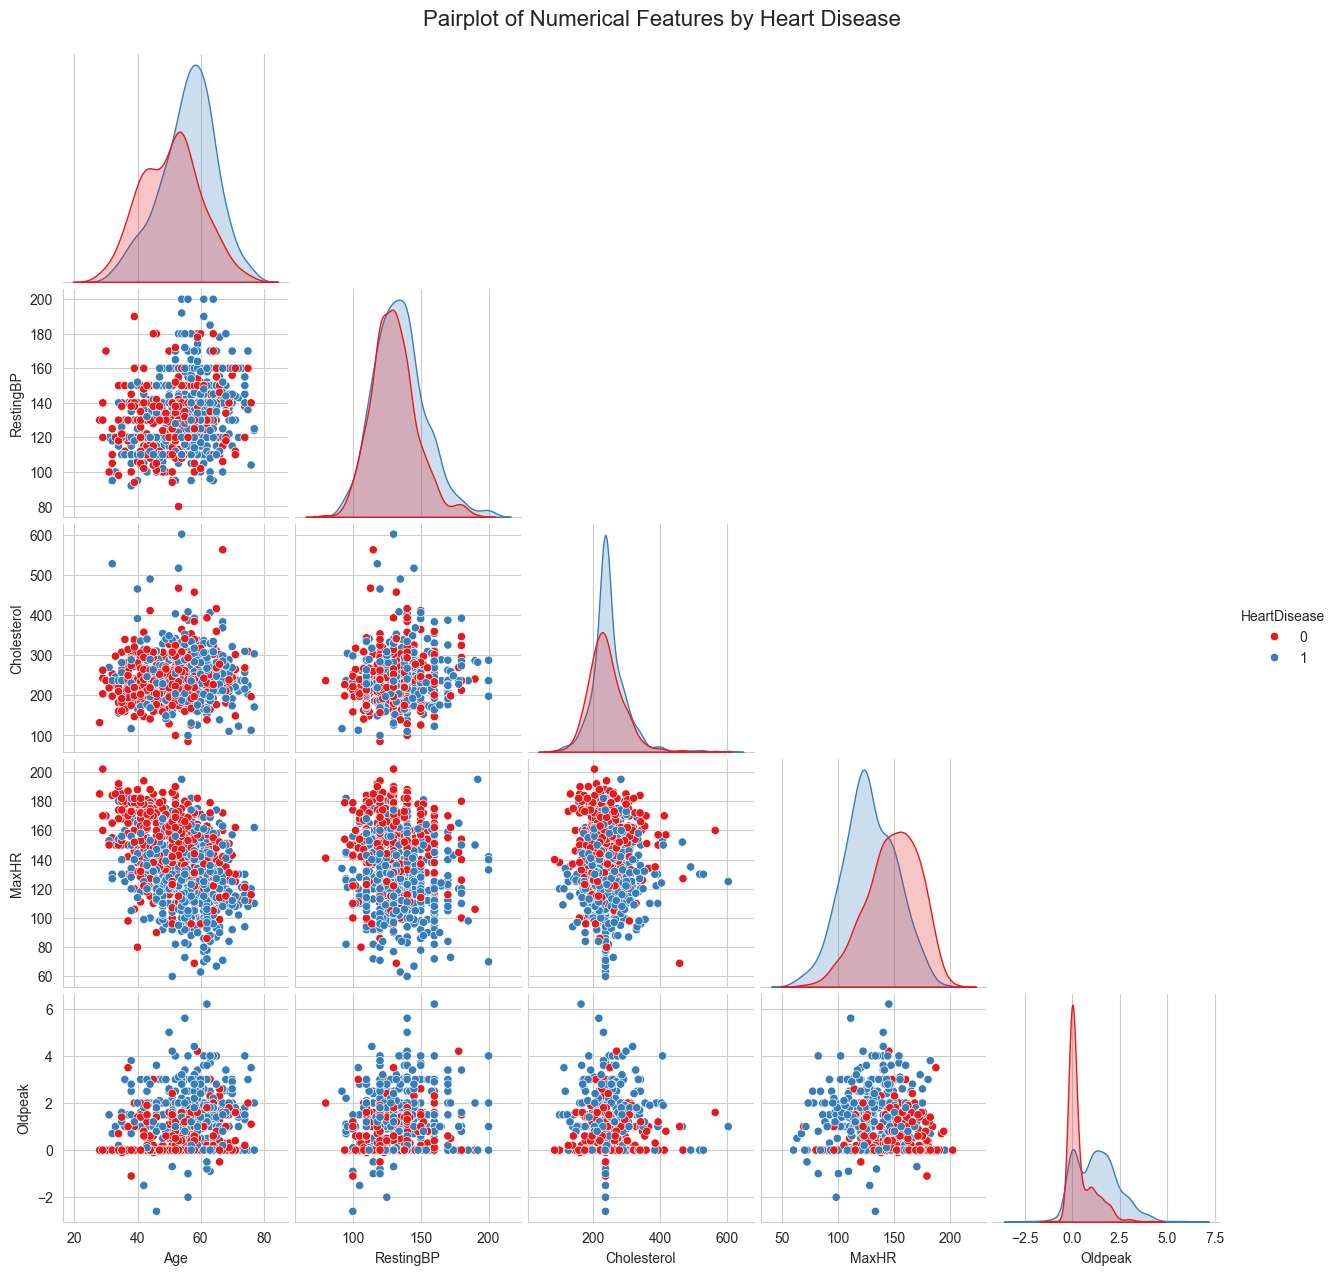

In [85]:
# Pair Plot for numerical features colored by HeartDisease

import seaborn as sns
import matplotlib.pyplot as plt

# Drop FastingBS from the pairplot since it's a binary feature
pairplot_cols = df.select_dtypes(include=["int64", "float64"]).columns.drop(["FastingBS"])
sns.pairplot(data=df[pairplot_cols], hue="HeartDisease", palette="Set1", corner=True, diag_kind="kde")
plt.suptitle("Pairplot of Numerical Features by Heart Disease", y=1.02, fontsize=16)
plt.show()

## __OBSERVATION:__

- The pair plot further confirms the strong preDictors identified previously in the bivariate analysis and correlation matrix. Based on the pair plot of the dataset, 

        - RestingBP and Cholesterol do not show a clear separation between patients with and without heart disease, which suggests that they may not be strong predictors on their own.
        - Oldpeak and MaxHR show a clear separation between patients with and without heart disease. Patients with heart disease tend to have higher oldpeak values and lower MaxHR values. This confirms that oldpeak and MaxHR are indeed strong predictors of heart disease.